<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_2_Disease_Detection/TeaLeafDiseaseDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


Mounted at /content/drive


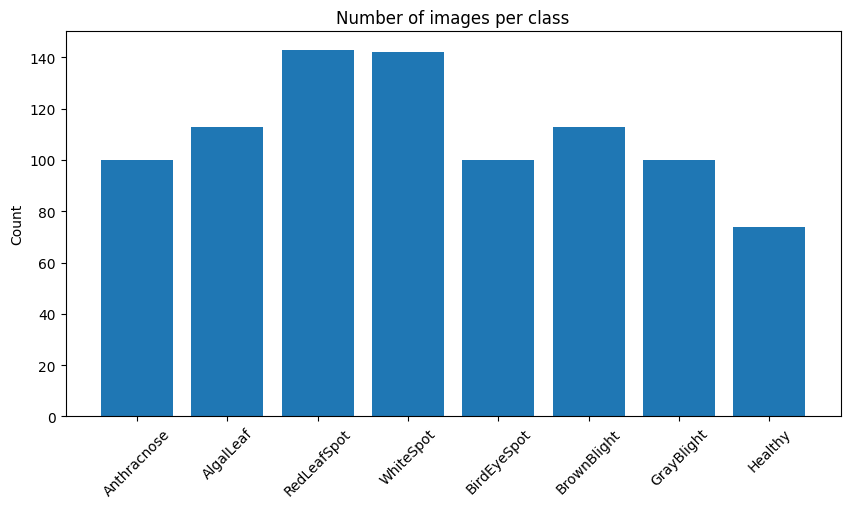

{'Anthracnose': 100,
 'AlgalLeaf': 113,
 'RedLeafSpot': 143,
 'WhiteSpot': 142,
 'BirdEyeSpot': 100,
 'BrownBlight': 113,
 'GrayBlight': 100,
 'Healthy': 74}

In [2]:

dataset_dir = "/content/drive/MyDrive/TeaDiseaseDataset"

class_counts = {}
for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

plt.figure(figsize=(10,5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.show()

class_counts


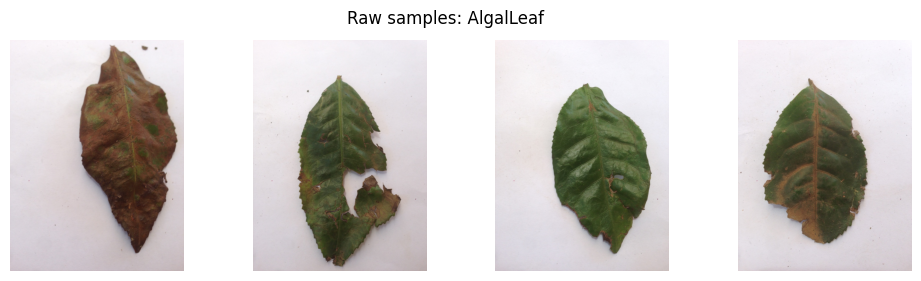

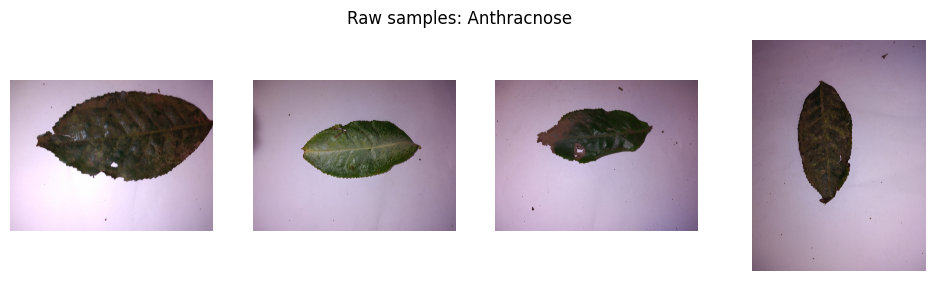

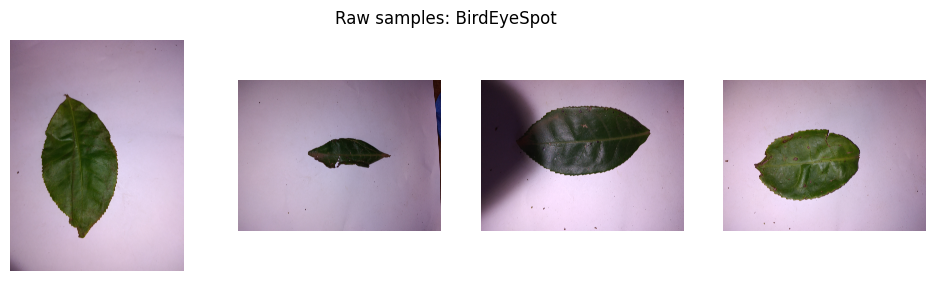

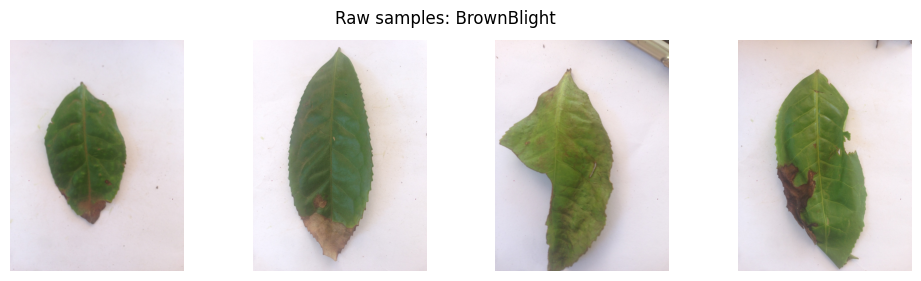

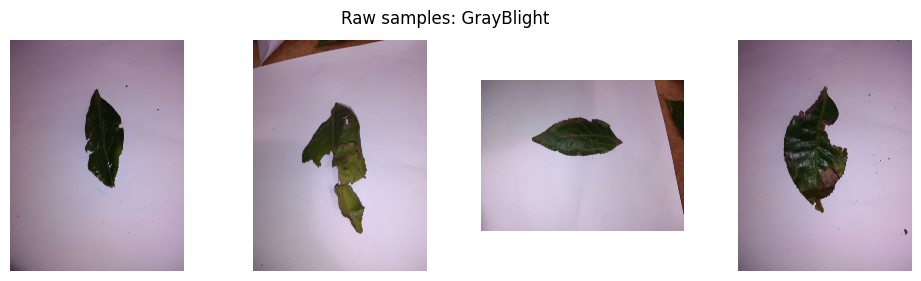

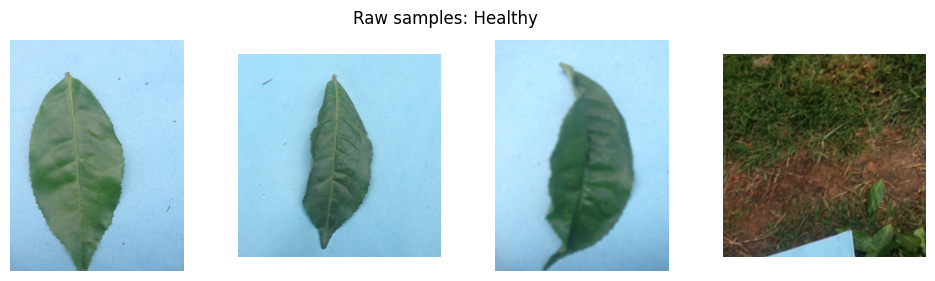

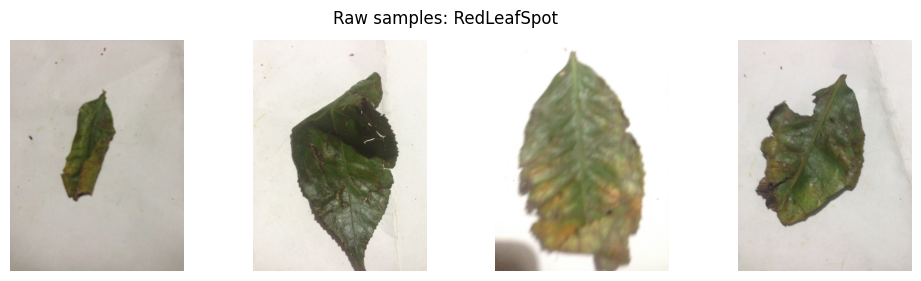

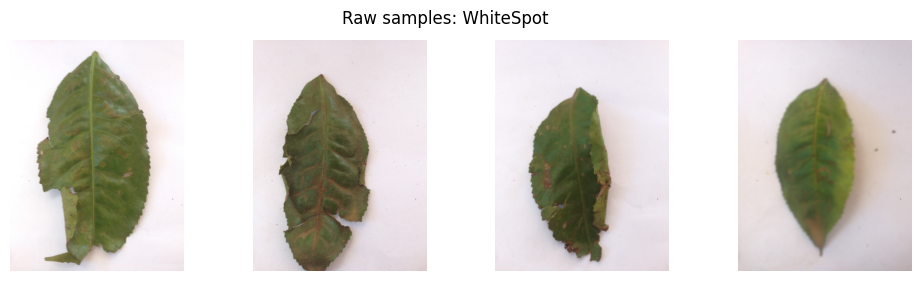

In [3]:
import random
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def show_samples_raw(dataset_dir, n=4):
    classes = sorted(os.listdir(dataset_dir))
    for cls in classes:
        cls_path = os.path.join(dataset_dir, cls)
        if not os.path.isdir(cls_path):
            continue

        imgs = random.sample(os.listdir(cls_path), n)
        plt.figure(figsize=(12,3))
        for i, img_name in enumerate(imgs):
            img_path = os.path.join(cls_path, img_name)
            img = image.load_img(img_path)
            plt.subplot(1,n,i+1)
            plt.imshow(img)
            plt.axis("off")
        plt.suptitle(f"Raw samples: {cls}")
        plt.show()

show_samples_raw(dataset_dir)


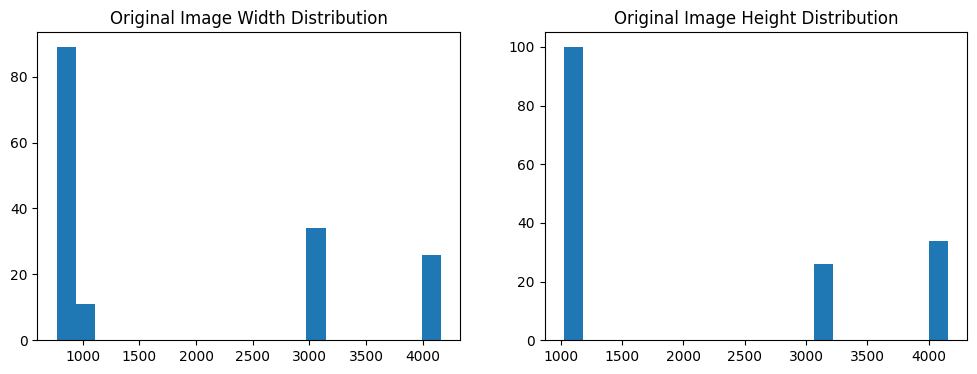

In [4]:
from PIL import Image
import random

sizes = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = random.sample(os.listdir(cls_path), min(20, len(os.listdir(cls_path))))
    for img_name in imgs:
        img_path = os.path.join(cls_path, img_name)
        with Image.open(img_path) as im:
            sizes.append(im.size)

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(widths, bins=20)
plt.title("Original Image Width Distribution")

plt.subplot(1,2,2)
plt.hist(heights, bins=20)
plt.title("Original Image Height Distribution")
plt.show()


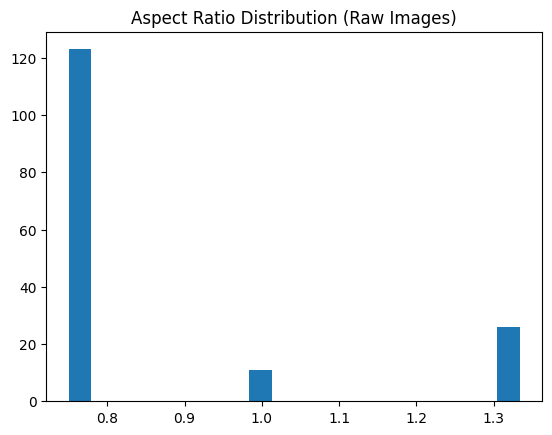

In [5]:
ratios = [w/h for w,h in sizes]

plt.hist(ratios, bins=20)
plt.title("Aspect Ratio Distribution (Raw Images)")
plt.show()


In [6]:
bad_files = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    for f in os.listdir(cls_path):
        path = os.path.join(cls_path, f)
        try:
            with Image.open(path) as im:
                im.verify()
        except:
            bad_files.append(path)

print("Corrupted images:", len(bad_files))


Corrupted images: 0


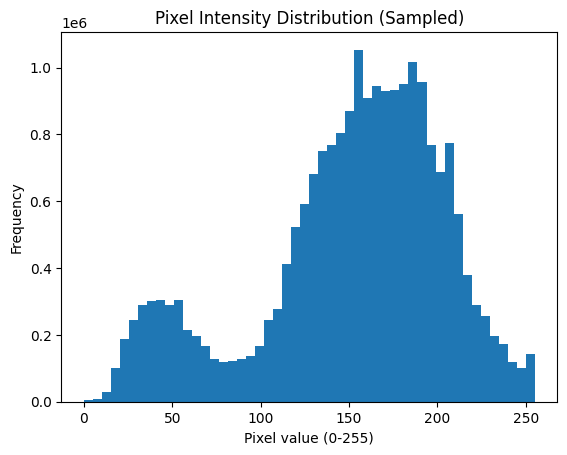

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import os

pixel_values = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = os.listdir(cls_path)

    # only sample few images per class
    sample_imgs = random.sample(imgs, min(5, len(imgs)))

    for img_name in sample_imgs:
        img_path = os.path.join(cls_path, img_name)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            # sample pixels instead of all pixels
            pixel_values.extend(img.flatten()[::10])

plt.hist(pixel_values, bins=50)
plt.title("Pixel Intensity Distribution (Sampled)")
plt.xlabel("Pixel value (0-255)")
plt.ylabel("Frequency")
plt.show()


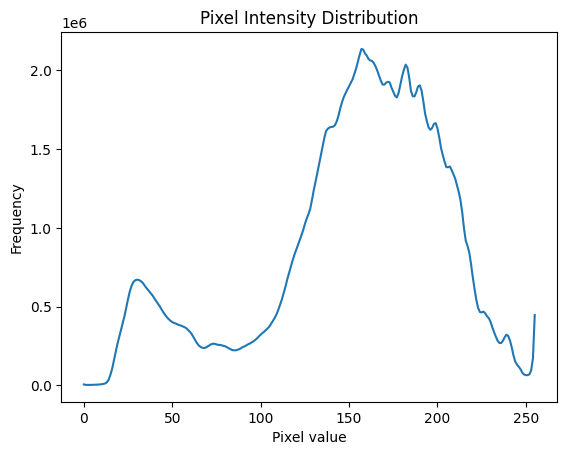

In [8]:
hist_total = np.zeros(256)

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = random.sample(os.listdir(cls_path), 5)

    for img_name in imgs:
        img = cv2.imread(os.path.join(cls_path, img_name), 0)
        hist = cv2.calcHist([img],[0],None,[256],[0,256])
        hist_total += hist.flatten()

plt.plot(hist_total)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()


# Pre-processing

In [ ]:

base_output = "/content/drive/MyDrive/TeaDataset_Split"
train_dir = os.path.join(base_output, "Train")
val_dir   = os.path.join(base_output, "Valid")
test_dir  = os.path.join(base_output, "Test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

split_ratio = (0.7, 0.15, 0.15)

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    images = os.listdir(cls_path)
    random.shuffle(images)

    total = len(images)
    train_end = int(split_ratio[0] * total)
    val_end   = train_end + int(split_ratio[1] * total)

    splits = {
        train_dir: images[:train_end],
        val_dir: images[train_end:val_end],
        test_dir: images[val_end:]
    }

    for split_dir, img_list in splits.items():
        cls_split_dir = os.path.join(split_dir, cls)
        os.makedirs(cls_split_dir, exist_ok=True)

        for img in img_list:
            shutil.copy(
                os.path.join(cls_path, img),
                os.path.join(cls_split_dir, img)
            )


In [ ]:

train_dir = "/content/drive/MyDrive/TeaDataset_Split/Train"
val_dir   = "/content/drive/MyDrive/TeaDataset_Split/Valid"
test_dir  = "/content/drive/MyDrive/TeaDataset_Split/Test"


In [ ]:
img_height = 224
img_width  = 224
batch_size = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    #rotation_range=20,
    #zoom_range=0.15,
    #width_shift_range=0.1,
    #height_shift_range=0.1,
    #horizontal_flip=True

    #rotation_range=30,
    #zoom_range=0.25,
    #width_shift_range=0.15,
    #height_shift_range=0.15,
    #brightness_range=[0.7, 1.3],
    #shear_range=0.15,
    #horizontal_flip=True,
    #fill_mode="nearest"

    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

num_classes = train_gen.num_classes


Found 618 images belonging to 8 classes.
Found 130 images belonging to 8 classes.
Found 137 images belonging to 8 classes.


In [ ]:

# balancing imbalanced training dataset

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get labels from generator
classes = train_gen.classes
class_labels = np.unique(classes)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=classes
)

class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)


Found 618 images belonging to 8 classes.
Class Weights: {0: np.float64(0.9778481012658228), 1: np.float64(1.1035714285714286), 2: np.float64(1.1035714285714286), 3: np.float64(0.9778481012658228), 4: np.float64(1.1035714285714286), 5: np.float64(1.5147058823529411), 6: np.float64(0.7725), 7: np.float64(0.7803030303030303)}


In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(img_height, img_width, 3)
)

base_model.trainable = False  # freeze backbone

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0.0005))(x)

x = Dropout(0.35)(x)
outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    #loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "MobileNetV2_TeaDisease.h5",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

epochs = 25

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)



/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.2221 - loss: 2.4626 
Epoch 1: val_accuracy improved from -inf to 0.55385, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 312s 15s/step - accuracy: 0.2251 - loss: 2.4464 - val_accuracy: 0.5538 - val_loss: 1.3906
Epoch 2/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4989 - loss: 1.4816
Epoch 2: val_accuracy improved from 0.55385 to 0.70000, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.4988 - loss: 1.4800 - val_accuracy: 0.7000 - val_loss: 1.1507
Epoch 3/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5667 - loss: 1.3339
Epoch 3: val_accuracy improved from 0.70000 to 0.71538, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.5678 - loss: 1.3303 - val_accuracy: 0.7154 - val_loss: 1.0448
Epoch 4/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6412 - loss: 1.2570
Epoch 4: val_accuracy improved from 0.71538 to 0.77692, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.6413 - loss: 1.2542 - val_accuracy: 0.7769 - val_loss: 1.0138
Epoch 5/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6918 - loss: 1.0927
Epoch 5: val_accuracy did not improve from 0.77692
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.6915 - loss: 1.0927 - val_accuracy: 0.7538 - val_loss: 0.9907
Epoch 6/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7097 - loss: 1.0666
Epoch 6: val_accuracy did not improve from 0.77692
20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.7107 - loss: 1.0652 - val_accuracy: 0.7692 - val_loss: 0.9467
Epoch 7/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7330 - loss: 0.9941
Epoch 7: val_accuracy did not improve from 0.77692
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7325 - loss: 0.9937 - val_accuracy: 0.7615 - val_loss: 0.9276
Epoch 8/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7347 - loss: 0.9781
Epoch 8: val_accuracy did not improve from 0.77692
20/2

20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7673 - loss: 0.9127 - val_accuracy: 0.7923 - val_loss: 0.8963
Epoch 10/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7748 - loss: 0.9582
Epoch 10: val_accuracy improved from 0.79231 to 0.80769, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7749 - loss: 0.9578 - val_accuracy: 0.8077 - val_loss: 0.9156
Epoch 11/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7525 - loss: 0.9474
Epoch 11: val_accuracy improved from 0.80769 to 0.81538, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7530 - loss: 0.9468 - val_accuracy: 0.8154 - val_loss: 0.8833
Epoch 12/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7895 - loss: 0.8629
Epoch 12: val_accuracy did not improve from 0.81538
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7897 - loss: 0.8637 - val_accuracy: 0.8154 - val_loss: 0.8611
Epoch 13/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7721 - loss: 0.9001
Epoch 13: val_accuracy improved from 0.81538 to 0.83846, saving model to MobileNetV2_TeaDisease.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7722 - loss: 0.8996 - val_accuracy: 0.8385 - val_loss: 0.8427
Epoch 14/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7835 - loss: 0.9171
Epoch 14: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7834 - loss: 0.9165 - val_accuracy: 0.7769 - val_loss: 0.8908
Epoch 15/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7653 - loss: 0.8989
Epoch 15: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7665 - loss: 0.8975 - val_accuracy: 0.7923 - val_loss: 0.9031
Epoch 16/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7987 - loss: 0.8751
Epoch 16: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7992 - loss: 0.8746 - val_accuracy: 0.8308 - val_loss: 0.8569
Epoch 17/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8102 - loss: 0.8579
Epoch 17: val_accuracy did not improve from 0.83

In [ ]:

# Unfreeze the top layers of MobileNetV2
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False


In [ ]:


from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
fine_tune_epochs = 20
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=fine_tune_epochs,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4679 - loss: 1.6364
Epoch 1: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accuracy: 0.4689 - loss: 1.6312 - val_accuracy: 0.8308 - val_loss: 0.6519
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5520 - loss: 1.3806
Epoch 2: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.5519 - loss: 1.3791 - val_accuracy: 0.8308 - val_loss: 0.6494
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6006 - loss: 1.1877
Epoch 3: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.6019 - loss: 1.1855 - val_accuracy: 0.8000 - val_loss: 0.6508
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6574 - loss: 1.0679
Epoch 4: val_accuracy did not improve from 0.83846
20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.6567 - loss: 1.0674 - val_accuracy: 0.8077 - val_loss: 0.6538
Epoc

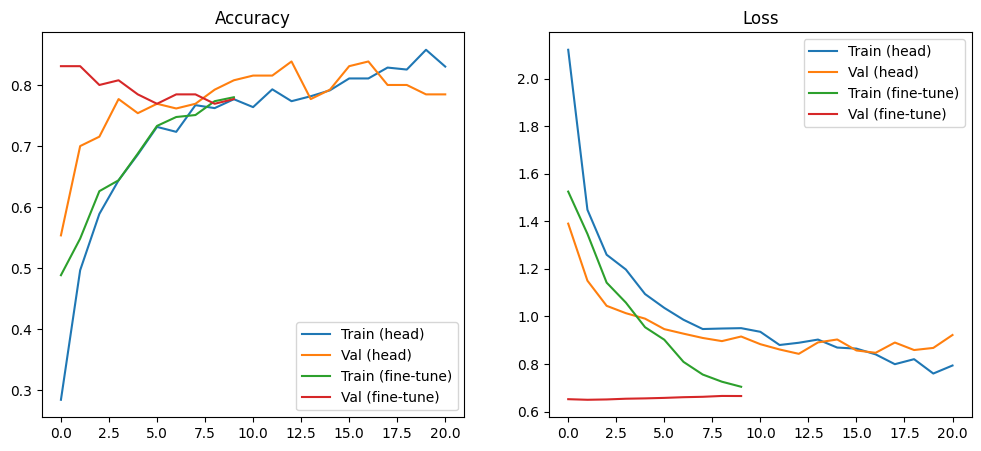

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Train (head)")
plt.plot(history.history["val_accuracy"], label="Val (head)")
plt.plot(history_fine.history["accuracy"], label="Train (fine-tune)")
plt.plot(history_fine.history["val_accuracy"], label="Val (fine-tune)")
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Train (head)")
plt.plot(history.history["val_loss"], label="Val (head)")
plt.plot(history_fine.history["loss"], label="Train (fine-tune)")
plt.plot(history_fine.history["val_loss"], label="Val (fine-tune)")
plt.title("Loss")
plt.legend()
plt.show()


In [ ]:

#  Evaluate on Train Set
train_loss, train_acc = model.evaluate(train_gen, verbose=1)
print(f"Train Accuracy: {train_acc*100:.2f}%")

# Evaluate on Validation Set
val_loss, val_acc = model.evaluate(val_gen, verbose=1)
print(f"Validation Accuracy: {val_acc*100:.2f}%")

# Evaluate on Test Set
test_loss, test_acc = model.evaluate(test_gen, verbose=1)
print(f"Test Accuracy: {test_acc*100:.2f}%")



20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.8901 - loss: 0.4866
Train Accuracy: 87.22%
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8103 - loss: 0.6422
Validation Accuracy: 83.08%
5/5 ━━━━━━━━━━━━━━━━━━━━ 50s 12s/step - accuracy: 0.7783 - loss: 0.6900
Test Accuracy: 81.02%


5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step


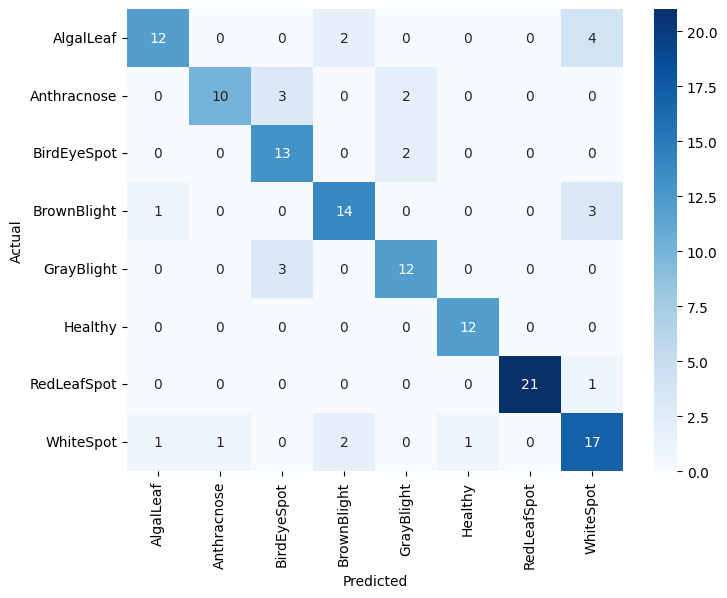

              precision    recall  f1-score   support

   AlgalLeaf       0.86      0.67      0.75        18
 Anthracnose       0.91      0.67      0.77        15
 BirdEyeSpot       0.68      0.87      0.76        15
 BrownBlight       0.78      0.78      0.78        18
  GrayBlight       0.75      0.80      0.77        15
     Healthy       0.92      1.00      0.96        12
 RedLeafSpot       1.00      0.95      0.98        22
   WhiteSpot       0.68      0.77      0.72        22

    accuracy                           0.81       137
   macro avg       0.82      0.81      0.81       137
weighted avg       0.82      0.81      0.81       137



In [ ]:

y_true = test_gen.classes
y_pred = np.argmax(model.predict(test_gen), axis=1)

cm = confusion_matrix(y_true, y_pred)
class_names = list(test_gen.class_indices.keys())

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))



In [ ]:
from tensorflow.keras.preprocessing import image

img_path = "/content/drive/MyDrive/DiseaseDataset/Test/Healthy/Healthy603.jpg"

img = image.load_img(img_path, target_size=(img_height, img_width))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

pred = model.predict(img_array)
pred_class = class_names[np.argmax(pred)]
confidence = np.max(pred)

print("Predicted:", pred_class)
print("Confidence:", confidence)


KeyboardInterrupt: 

In [ ]:
# saving full model

model.save("/content/drive/MyDrive/MobileNetV2_TeaDisease_Final.keras")



In [ ]:
# loading saved model

from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/MobileNetV2_TeaDisease_Final.keras")


In [ ]:
# saving class nmes

import json

class_names = list(train_gen.class_indices.keys())

with open("/content/drive/MyDrive/class_names.json", "w") as f:
    json.dump(class_names, f)


In [ ]:
# loading the saved class names

with open("/content/drive/MyDrive/class_names.json") as f:
    class_names = json.load(f)

# After loading the saved model, testing with images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from tensorflow.keras.models import load_model
import json
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image



Mounted at /content/drive


In [ ]:
# Load trained model
model = load_model("/content/drive/MyDrive/MobileNetV2_TeaDisease_Final.keras")

# Load class names
with open("/content/drive/MyDrive/class_names.json") as f:
    class_names = json.load(f)

print("Model loaded successfully")
print("Classes:", class_names)



Model loaded successfully
Classes: ['AlgalLeaf', 'Anthracnose', 'BirdEyeSpot', 'BrownBlight', 'GrayBlight', 'Healthy', 'RedLeafSpot', 'WhiteSpot']


In [ ]:
img_height = 224
img_width = 224

img_path = "/content/drive/MyDrive/CheckDisease/grayblight1.jpg"

img = image.load_img(img_path, target_size=(img_height, img_width))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)


In [ ]:
pred = model.predict(img_array)

pred_index = np.argmax(pred)
pred_class = class_names[pred_index]
confidence = pred[0][pred_index]

print("Predicted Disease:", pred_class)
print("Confidence:", f"{confidence*100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step
Predicted Disease: GrayBlight
Confidence: 53.98%


#